## 1. Introduction

<div style="padding: 5px; border-left: 5px solid #ceb431; margin-bottom: 10px;">
    <strong>October 30th, 2026</strong>
</div>

With the last notebook successfully implementing the Pauli-X and CNOT gates, we are ready to move on to implementing a method that simulates quantum measurement.

The real measurement mechanics of qubits is one of the things that lead to my initial quantum intrigue. One of the first things I remember learning in this, now rather deep, rabbithole was the term "shots" in relation to iterative measurement of qubits. I found it so interesting yet intuitive that we are using histograms to measure these things that seem immeasurable at first glance. That's why, I am elated to be this deep into this project, ready to begin a simple shot measurement method to my quantum state simulation.

## 2. Building the Measure Method

I'm thinking I'll just implement a measure(_shots_) method that runs np.choice x amount of times and returns a hyper-histogrammable format. To see how it should be formatted, I'll take a look at how a matplotlib histogram signature looks:

```matplotlib.pyplot.hist(x, bins=None, *, range=None, density=False, weights=None, cumulative=False, bottom=None, histtype='bar', align='mid', orientation='vertical', rwidth=None, log=False, color=None, label=None, stacked=False, data=None, **kwargs)``` From: [matplotlib documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)

Since a given circuit just outputs one of $2^n$ states (all possibilites in our ```QuantumCircuit.state_vector```), we just need a bin for each state, with a value that increases every time that possiblity is chosen by our ```np.choice``` call. This list of values is going to be just as big as our state vector, and will have the exact same index representation. Therefore, we can just initialize a np array of zeros, add add to that indexes value when it is drawn:

In [1042]:
import shutil
import matplotlib.pyplot as plt
import numpy as np

shutil.copy("quantum_circuit_nb04.py", "quantum_circuit_nb05.py")

'quantum_circuit_nb05.py'

In [1043]:
%run -i quantum_circuit_nb05.py

In [1044]:
%%writefile -a quantum_circuit_nb05.py

    def measure(self, shots):
        probabilities = np.abs(self.state_vector)**2 #Convert to %

        measurements = np.zeros(self.size)

        choices = np.random.choice(np.arange(len(probabilities)), size=shots, p=probabilities)  # p here is weighting the choices
        
        np.add.at(measurements, choices, 1)
        
        return measurements

Appending to quantum_circuit_nb05.py


In [1045]:
%run -i quantum_circuit_nb05.py

circuit = QuantumCircuit(2)

circuit.h(0).cnot(0, 1)  # Bell State

print(circuit.measure(1000))

[501.   0.   0. 499.]


Nice, lets see this do some histograms:

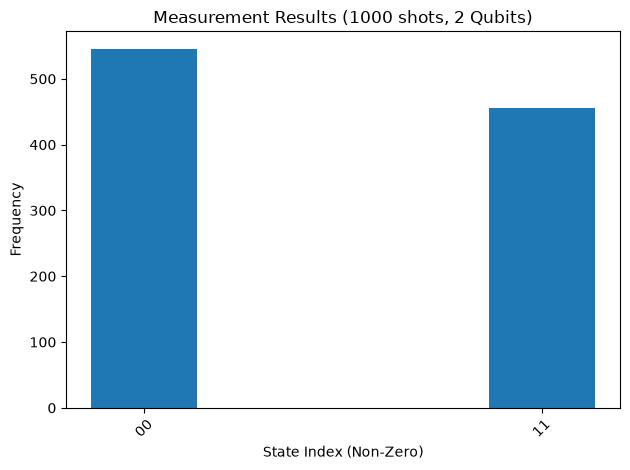

In [1046]:
def histogram_measurements(m):
    indices = np.arange(len(m))

    active_indices = np.where(m > 0)[0]
    active_counts  = m[active_indices]

    labels = [np.binary_repr(idx, width=int(np.log2(len(m)))) for idx in active_indices]

    plt.xticks(active_indices, labels, rotation=45)
    plt.bar(active_indices, active_counts)

    plt.xlabel('State Index (Non-Zero)')
    plt.ylabel('Frequency')

    plt.title(f"Measurement Results ({int(np.sum(m))} shots, {int(np.log2(len(m)))} Qubits)")
    
    plt.tight_layout()

    plt.show()

histogram_measurements(circuit.measure(1000))


Awesome, now let's try some bigger circuits:

[0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]


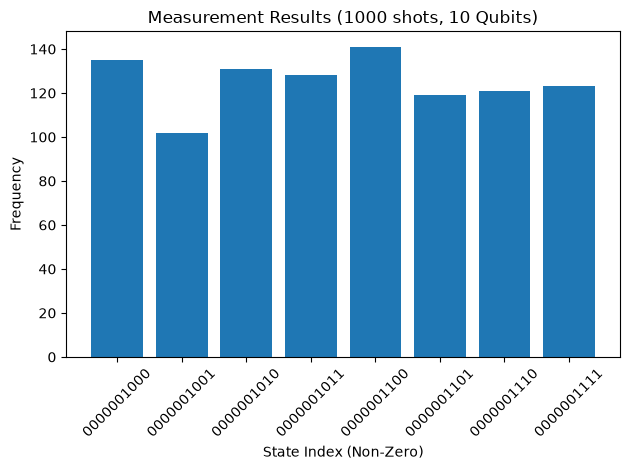

In [ ]:
ten_q_circuit = QuantumCircuit(10)

ten_q_circuit.h(0).h(1).px(3).px(2).cnot(0, 1).h(2)

histogram_measurements(ten_q_circuit.measure(1000))

Great! One last one:

[0.70710678+0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
 0.        +0.j 0.        +0.j]


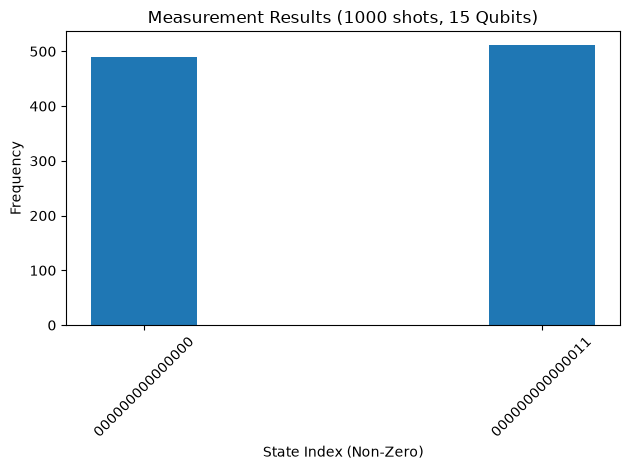

In [ ]:
ten_q_circuit = QuantumCircuit(15)

ten_q_circuit.h(0).cnot(0, 1)

histogram_measurements(ten_q_circuit.measure(1000))